<a href="https://colab.research.google.com/github/gnperdue/SaturdayMorningQuantum/blob/main/QuantumComputing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantum Computing in 2 Hours*

*Actually learning programming in a short period of time is more challenging than you might think...

<img src="images/1fl5yi6bbpzz.png" height=500>

**To use this notebook: click a cell to edit it, and press Shift+Return to run it (code or text).**

In [1]:
#@title "Software Setup [Run this cell with Shift+Enter!]"
try:
    import numpy as np
    import qiskit
    from qiskit import QuantumCircuit
    from qiskit_aer import AerSimulator
except ImportError:
    import subprocess, sys
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install",
         "qiskit==2.3.1", "qiskit-aer==0.17.2", "-q"]
    )
    import numpy as np
    import qiskit
    from qiskit import QuantumCircuit
    from qiskit_aer import AerSimulator

print(f"NumPy {np.__version__}")
print(f"Qiskit {qiskit.__version__}")

NumPy 2.4.3
Qiskit 2.3.1


This notebook was last tested with NumPy 2.4.3, Qiskit 2.3.1 and Qiskit Aer 0.17.2. Where the setup cell has to install software (as on Colab), it installs exactly those versions of Qiskit and Qiskit Aer, so your results should match ours.

We also use some functions [originally written by Dr. C. Moran](https://www.frontiersin.org/articles/10.3389/fphy.2018.00069/full) to draw qubits.

In [2]:
#@title "NumPy Qubits and Bloch sphere plotting functions [Run me!]"
zero_qubit=np.matrix('1; 0')
one_qubit=np.matrix('0; 1')
plus_qubit=1/np.sqrt(2)*np.matrix('1; 1')
minus_qubit=1/np.sqrt(2)*np.matrix('1; -1')
clockwisearrow_qubit=1/np.sqrt(2)*np.matrix([[1],[complex(0,1)]])
counterclockwisearrow_qubit=1/np.sqrt(2)*np.matrix([[1],[-complex(0,1)]])

import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
def get_bloch_coordinates(qubit):
    def get_x_bloch(qubit):
        qubit_x_basis=1./np.sqrt(2)*np.matrix('1 1; 1 -1')*qubit
        prob_zero_qubit=(qubit_x_basis.item(0)*qubit_x_basis.item(0).conjugate()).real
        prob_one_qubit=(qubit_x_basis.item(1)*qubit_x_basis.item(1).conjugate()).real
        return prob_zero_qubit-prob_one_qubit

    def get_y_bloch(qubit):
        qubit_y_basis=1./np.sqrt(2)*np.matrix('1 1; 1 -1')*np.matrix([[1,0],[0,-complex(0,1)]])*qubit
        prob_zero_qubit=(qubit_y_basis.item(0)*qubit_y_basis.item(0).conjugate()).real
        prob_one_qubit=(qubit_y_basis.item(1)*qubit_y_basis.item(1).conjugate()).real
        return prob_zero_qubit-prob_one_qubit

    def get_z_bloch(qubit):
        qubit_z_basis=qubit
        prob_zero_qubit=(qubit_z_basis.item(0)*qubit_z_basis.item(0).conjugate()).real
        prob_one_qubit=(qubit_z_basis.item(1)*qubit_z_basis.item(1).conjugate()).real
        return prob_zero_qubit-prob_one_qubit
    return (get_x_bloch(qubit),get_y_bloch(qubit),get_z_bloch(qubit))

def plot_bloch(qubit,color='b',ax=None):
    if not ax:
        fig = plt.figure(figsize=(10, 10))
        ax = fig.add_subplot(111, projection='3d')

        # draw sphere
        u, v = np.mgrid[0:2*np.pi:20j, 0:np.pi:10j]
        x = np.cos(u)*np.sin(v)
        y = np.sin(u)*np.sin(v)
        z = np.cos(v)
        ax.plot_wireframe(x, y, z, color="k",alpha=.1)
        ax.grid(False)

    coordinates=get_bloch_coordinates(qubit)
    ax.quiver([0],[0],[0],[coordinates[0]],[coordinates[1]],[coordinates[2]],length=1,color=color,arrow_length_ratio=0.3)
    ax.set_xlim([-1,1])
    ax.set_ylim([-1,1])
    ax.set_zlim([-1,1])
    ax.set_xlabel('x: |"-"> to |"+">')
    ax.set_ylabel('y: |"↺"> to |"↻">')
    ax.set_zlabel('z: |"1"> to |"0">')
    ax.view_init(azim=20)
    return ax

i_ = complex(0, 1)
H = 1. / np.sqrt(2) * np.matrix('1 1; 1 -1')
X = np.matrix('0 1; 1 0')
Y = np.matrix([[0, -i_], [i_, 0]])
Z = np.matrix([[1, 0], [0, -1]])

def pretty_print_number(amnt):
    the_string = locale.format_string("%12.0f", amnt, grouping=True)
    print("{}".format(the_string))

# other libraries
import locale
import pprint
import scipy.optimize

## Introduction and front matter

This is a [Jupyter](https://jupyter.org/) notebook: text, graphics and runnable code in one document. Run it locally with [JupyterLab](https://jupyterlab.readthedocs.io/) or in the cloud with [Google Colab](https://colab.research.google.com) (free with a Google account).

The code is [Python](https://www.python.org/). If you've never seen it, don't worry: it's easy to read, and the [official beginner's guide](https://wiki.python.org/moin/BeginnersGuide) is great.

### Outline

0. Brief aside on entanglement and superposition.
1. Computation is tied to _physical systems_.
2. "Classical" computation with the _circuit model_.
3. Limitations of the classical computing model.
4. Distinguishing features of _quantum computation_.
5. The quantum circuit model — lines and gates.
6. QASM — the Quantum Assembly Language.
7. Digital quantum computing — error correction and the fault-tolerant gate set.
8. Fault-tolerant algorithms — what quantum computers will be good at.
9. Two demos — a quantum adder, and a dial with two buttons.
10. What to remember.
11. Bonus — detecting eavesdroppers on a quantum network.

## Measurements, Superposition, and Entanglement

Quantum computing draws its power from two phenomena unique to quantum mechanics: **superposition** and **entanglement**. To understand them, we first need to see how **measurement** works at the quantum scale.

### Two-level Systems

#### Classical Example: A coin

A coin is a classical two-level system: it's always either Heads or Tails. Abstract it one level up and you have a **bit**, 0 or 1. Let 0 be Heads and 1 be Tails.

<img src="images/ht01.png">

A row of coins can encode a number in binary: TTHTT is 0b11011 = 27. (More on binary below.)

<img src="images/tthtt.png">

#### Quantum Example: A _Spin_

Our quantum two-level system is a **spin**. "Spin" is both a label and a concept: a particle's built-in angular momentum. (Picturing a tiny spinning top is _not_ correct, but it's a useful mental model.)

Even briefly explaining spin in quantum mechanics is more than we have time for. Please accept that a "spin-1/2 particle" has exactly two levels, `Up` and `Down`. Call one 0 and the other 1, and we have a **qubit**, a *quantum* bit.

<img src="images/christophe-hautier-902vnYeoWS4-unsplash.jpg" height=400>

Photo by [Christophe Hautier](https://unsplash.com/@hautier)

But if spin is angular momentum, why can't it point at any angle? Why only two levels? This oddness is where quantum mechanics, and the word _quantum_, comes from!

### Measurement

Suppose a device measures a particle's spin **along a direction**. Call "up" `z`; `x` points right, and `y` points "into the page." What do we get if we measure along `z`?

<img src="images/spin.png" height=400>

**We always get `Up` or `Down`, never a fraction like `0.5 Up`.** Random spins give a roughly even mix, and measuring the same spin again always gives the same result.

<img src="images/spin2.png" height=400>

Now take a bunch of spins we measured `Up` along `z`, and measure them along `x`. What do you expect to find?

<img src="images/spin3.png" height=400>

Again only `Right` (`+x`) or `Left` (`-x`), never `0.5 Right`, in an even mix. What is going on?

The real insight comes when we sort them into `Right` and `Left` and measure each group along `z` again. What do you think we find?

<img src="images/spin4.png" height=400>

Both groups are an even mix of `Up` and `Down`! Yet measuring along the same axis twice in a row always gives the same answer.

Classical things don't behave like this. A die on a table doesn't change its top face because you looked at it from the side!

**At the quantum scale, measurement is not a gentle act**: it disturbs the particle, and its results are *quantized*. (That measuring along `x` scrambles a later measurement along `z` is the famous [uncertainty principle](https://en.wikipedia.org/wiki/Uncertainty_principle).)

### Superposition

One way to understand this is **superposition**: a quantum particle can be in several states at once!

Our choice of `z` as "up" was arbitrary, and `Up-Down` is at 90 degrees to `Left-Right`. Being **fully** `Up` is the same as being a 50-50 **superposition** of `Left` and `Right`:

$$
|U\rangle = \frac{1}{\sqrt{2}} \left( |L\rangle + |R\rangle \right).
$$

(The funny-looking brackets are called "bra-ket" notation.)

<img src="images/spin-xz.png" height=400>

Measuring along `x` gives `Left` or `Right`, 50-50. **Measurement collapses the superposition!** But `Right` is itself a 50-50 superposition of `Up` and `Down`, which is why measuring along `z` again gives an even mix.

One of the most famous superpositions of all time...

<img src="images/blog_schrodinger1.jpg">

What if we measure at an angle that isn't 90 degrees from `z`? Again we find a superposition, but the numbers multiplying each state, the **amplitudes**, depend on the angle, so the mix isn't even. **The probability of each outcome is its amplitude squared.** We still only ever find one value or the other.

We always measure _something_, so the squared amplitudes **must add up to 1**. For

$$
|U\rangle = \cos \theta |L\rangle + \sin \theta |R\rangle
$$

they do, because $\cos^2 \theta + \sin^2 \theta = 1$ for any $\theta$.

Since we only ever measure amplitudes _squared_, amplitudes can be negative. They can even be _complex_: $a + i b$, where $a$ and $b$ are ordinary numbers and $i$ is a special constant with $i^2 = -1$.

For a complex amplitude, "squared" means the _modulus_ squared:

$$
\left| a + i b \right|^2 = (a + i b) (a - i b) = a^2 + b^2
$$

We'll write complex amplitudes with Greek letters, so a general state is

$$
|U\rangle = \alpha |L\rangle + \beta |R\rangle, \qquad |\alpha|^2 + |\beta|^2 = 1.
$$

It's often handy to write a complex number as $r e^{i \theta}$, using $e^{ix} = \cos x + i \sin x$. Then the modulus squared is simple:

$$
\left| r e^{i\theta} \right|^2 = \left(r e^{i\theta}\right)\left(r e^{-i\theta}\right) = r^2
$$

Superposition is really weird, but for one spin it isn't obviously _useful_. It becomes *very* useful with many spins, because the space of possible states gets enormous. That leads us to *entanglement.*

### Entanglement

To combine quantum systems we use *tensor products*. Two spins have four basis states, `UU`, `UD`, `DU` and `DD`, where

$$
|U\rangle \otimes |U\rangle = |UU\rangle,
$$

and a two-spin system can be in a superposition of all four. $N$ spins have $2^N$ basis states: the state space grows *exponentially* with the number of qubits.

How many numbers does it take to describe a state? One spin has two complex amplitudes, which is four real numbers. Normalization fixes one, and an overall phase, which **always** disappears in a measurement, can be pulled out:

$$
r_1 e^{i\theta_1} |U\rangle + r_2 e^{i\theta_2} |D\rangle \rightarrow \left(r_1 |U\rangle + \sqrt{1 - r_{1}^2}  e^{i\Delta\theta} |D\rangle \right)
$$

Only the _relative_ phase $\Delta\theta$ matters. Four numbers minus two constraints: one spin takes **two** numbers.

What about two spins?

$$
|\Psi\rangle = \alpha|UU\rangle + \beta|UD\rangle + \gamma|DU\rangle + \kappa|DD\rangle
$$

is eight real numbers, with the same two constraints. That leaves **six**.

Six, not 2 × 2 = 4! What do the two extra numbers describe? *Entanglement*.

<img src="images/universal-eye-4bhhwmsYl-c-unsplash.jpg" height=500>

Photo by [Universal Eye](https://unsplash.com/@universaleye)

_Entangled systems are no longer independent systems._ Consider

$$
|s\rangle = \frac{1}{\sqrt{2}} \left(|UD\rangle - |DU\rangle \right).
$$

Each spin is equally likely to be up or down, so we know nothing about either one until we measure. But we have *complete knowledge about the pair*: they're opposite!

Nothing in classical physics works like this. It's like saying, "I know everything about that car over there (how fast it's going, which doors are open, what's playing on the radio), but nothing about any of its parts."

### The Power of Quantum

**Superposition and entanglement create the power of quantum computing**, but not the way you often hear. Many people believe a quantum computer runs many calculations in parallel. Even experts sometimes say this as shorthand, but it isn't *correct*.

A register of $n$ qubits holds **one** state with $2^n$ amplitudes, and a **linear** number of gates can make it very entangled. Each gate moves the **whole distribution** of amplitudes at once. A measurement returns one **sample** from that distribution, so a program can give a different answer on each run, and we run it many times.

So **a quantum computer efficiently builds a probability distribution that represents our problem, sloshes the whole distribution around, and then samples from it.** The art is to make the right answer the likely one.

This [Saturday Morning Breakfast Cereal comic](https://www.smbc-comics.com/comic/the-talk-3) explains it beautifully. Another favorite of mine from them: [be careful with hype!](https://www.smbc-comics.com/comic/quantum)

## Computation is performed by physical systems

Let's start with the big picture... What is _computation_?

<img src="images/matrix-code-rain1.jpg" height=500>

**Computation is manipulating a physical system according to rules and interpreting the result.** Can you think of any computation that doesn't involve a physical system?

Take an abacus: move the beads by the rules, and their new positions are the sum. The abacus doesn't "know" it added numbers, but we do.

<img src="images/giphy.gif">

An abacus is slow (though some people are [really fast](https://www.youtube.com/watch?v=GQtqlB-jXO0) with them), so today we use electronics. An _algorithm_ turns addition into rules for binary numbers (two-level systems!), transistors _simulate_ that algorithm with currents and voltages, and we _interpret_ the result (with our brains, starting a [turtles all the way down chain](https://en.wikipedia.org/wiki/Turtles_all_the_way_down)...).

There's some philosophy here! Why talk about quantum _computing_ in a physics class? Well, if computation _is_ physical systems simulating algorithms...

<img src="images/FaiPR_LXEAAU5uz.jpeg">

From a certain point of view, physics _is_ computing and computing _is_ physics. Some think that at the bottom of everything we'll find [information theory](https://en.wikipedia.org/wiki/Information_theory), and it will have to be _quantum_ information theory.

A quantum computer is an instrument that plays the base layer of physical reality, which sounds like something that belongs in a physics class!

## Classical circuit model

There are many universal models of computation (Turing machines, circuits, and so on). We'll use _circuits_, because that's how people reason about quantum programs today.

### Start with: Addition with binary numbers

<img src="images/10kindsofpeople.jpg">

A computer (a phone, a laptop) adds numbers in [_binary_](https://en.wikipedia.org/wiki/Binary_number), base 2. We're used to base 10:

```
765 = 7 x 10^2 + 6 x 10^1 + 5 x 10^0
```

Base 10 is so ingrained that we use base 10 to explain base 10!

Binary works the same way, with powers of two and the digits 0 and 1:

```
0b101 = 1 x 2^2 + 0 x 2^1 + 1 x 2^0 = 5
```

Binary suits physical computers because two-level systems are _physically_ simple, and electronics can flip them very fast. To add, we first "hardwire" some simple rules:

<img src="images/add_two_binary_numbers_rules.png" height="90">

<img src="images/add_three_binary_numbers_rules.png" height="90">

We store the two numbers in _registers_ (physical two-level systems like voltage levels or tiny magnets), and a third register gets the result plus a carry bit. Then we scan across the digits, applying the rules. Here we add 6 and 7:

<img src="images/binary_addition.png" height="150">

For more, try this [web app](https://chortle.ccsu.edu/AssemblyTutorial/zAppendixE/binaryAdd.html).

In [3]:
0b110 + 0b111

13

In [4]:
bin(13)

'0b1101'

So really, there are 0b10 kinds of people in the world.

Now, let's build some _circuits_...

### Logic gates

How do we build these rules into hardware? With [transistors that make _logic gates_](https://en.wikipedia.org/wiki/Transistor–transistor_logic). In a circuit diagram, lines carry bits (0's and 1's) and symbols are gates. A _truth table_ shows what each gate does to its inputs.

<img src="images/circuits/logic-gates.png" alt="Logic gates: NOT, AND, OR and XOR, with their truth tables" width=620>

Some composite gates are so popular they are often built as primitives:

<img src="images/circuits/nand-nor.png" alt="NAND and NOR, with their truth table" width=680>

Adding two bits (the first set of rules above) takes two inputs and two outputs, and an AND and an XOR do it. This is a _half adder_:

<img src="images/circuits/half-adder.png" alt="Half adder" width=480>

Two half adders and an OR gate make a _full adder_, which also takes a carry bit $c$:

<img src="images/circuits/full-adder.png" alt="Full adder" width=700>

Chain adders to add bigger numbers. For two 3-bit numbers:

<img src="images/circuits/cascaded-adder.png" alt="Cascaded adders" width=500>

**Exercise:** Verify this circuit performs addition correctly.

**Exercise:** Can you work out a circuit for binary multiplication?

This is the bottom of the software stack: logic gates built directly into hardware. A chip with billions of transistors is billions of these gates, churning out answers as current flows through them.

<img src="images/m1s.jpeg" alt="M1 chip family" height=400>

On top, you layer abstractions, all the way up to expressive programs that can, in principle, compute anything! And the bottom layer can be very simple: you can do everything with **only** `NAND` gates.

## Limits to "classical" computing

Can we really compute _everything_ this way? In principle, yes. In practice, an algorithm that needs too many steps could run longer than the lifetime of the universe.

We might know the algorithm that finds a molecule to cure cancer, and still never learn what the molecule is!

Say we simulate a molecule to compute a chemical property (like how strongly a drug binds to a protein). Electrons are two-level _quantum_ systems, so writing down the state of $N$ electrons, with all its _superposition_ and _entanglement_, takes $2^N$ numbers.

Time to wave my hands... (numbers are round and rough...)

<img src="images/giphy_5.gif" alt="Jazz hands">

Imagine 50 electrons matter for the molecule's chemistry. At one byte (8 bits) per number, that's this many gigabytes:

In [5]:
2**50 / 1e9

1125899.906842624

About a million gigabytes, the memory of a world-class supercomputer, so humans **can** do this. Now try a molecule with 100 important electrons. If $2^{50}$ is one world-class supercomputer, how many is $2^{100}$?

In [6]:
print("{:1.5g}".format(2**100 / 2**50))

1.1259e+15


A million billion supercomputers! Human civilization has maybe three of this class. **Exponential functions get REALLY big, REALLY fast!**

Transistor hardware has to brute-force the bookkeeping of superposition and entanglement, and the cost grows **exponentially** with the size of the system. Can [Moore's Law](https://en.wikipedia.org/wiki/Moore%27s_law) save us? Computing power has roughly doubled every two years for decades. Can we just wait?

<img src="images/giphy_4.gif">

No. Each doubling buys just **one more electron**. And Moore's Law is running out of room: transistors are approaching the size of atoms, and [Dennard scaling](https://en.wikipedia.org/wiki/Dennard_scaling) has already broken down, so we can't _turn on_ a whole chip at once or it will melt.

<img src="images/limits_to_classical_comp_m_alam_rigetti.png" height=400>

Figure courtesy of M. Sohaib Alam.

The resources we'd need are ludicrously beyond civilization's reach. But we'd really like to solve these problems: cancer sucks!

Maybe the problem is the hardware. What if we built a computer out of _quantum systems themselves_, and let nature do the heavy lifting?

Good idea! Doing this with the actual molecules is called "chemistry," and it is _great_. But a test tube answers one specific question: it isn't programmable, we can't use it as a step in a bigger algorithm, and it needs the actual stuff, which may be rare or expensive. What we want is a _programmable_ quantum system.

## Distinguishing features of Quantum computing

Simulating quantum systems classically is hard because superposition and entanglement take exponentially many numbers to track: the physics of our simulator is wrong for the problem. So what if the computer itself were quantum?

A _quantum computer_ manipulates _quantum states_ instead of voltages or wooden beads: it uses **qubits** instead of bits. Qubits can be in superpositions and can be entangled, so $n$ qubits have $2^n$ basis states. That exponential scaling is exactly what we need.

<img src="images/qubit_scaling_m_alam_rigetti.png">

Figure courtesy of M. Sohaib Alam.

The hardware looks nothing like a laptop. Our "computer" might be a _register_ of spins (say, trapped ions) that we push from one quantum state to another with laser pulses.

<img src="images/registerofqubits.png">

Some real quantum computing devices:

<img src="images/pictures-of-quantum-hardware.png">

From left to right: Google's superconducting transmon chip ([Sycamore](https://research.google/blog/quantum-supremacy-using-a-programmable-superconducting-processor/)), Fermilab's [superconducting radio frequency cavity](https://sqms.fnal.gov/research/), Quantinuum's [ion trap](https://www.quantinuum.com/hardware), Xanadu's [photonic chip](https://www.xanadu.ai/hardware).

Most quantum devices must be cooled to very close to absolute zero (not all: ion traps can run at room temperature) in [dilution refrigerators](https://en.wikipedia.org/wiki/Dilution_refrigerator), which look cool and show up in press photos all the time.

On the left, Fermilab scientists Dan Bowring and Rakshya Khatiwada work on a "dil fridge" that will use qubits as _detectors_ in physics experiments; on the right, a "promotional" photo from [Bluefors](https://bluefors.com/):

<img src="images/dil-fridges.png">

### What are quantum computers practically good for?

It's hard to say what the real "killer app" is yet. But we can be sure quantum computers will be good at _simulating quantum systems_: chemicals (like drugs), materials, black holes, nuclear matter, and so on. These are systems that are difficult to experiment on and impossible to calculate. We will *only* be able to learn about them with a quantum computer.

**From this perspective a quantum computer is first and foremost a _tool for discovery_, like a telescope or a particle accelerator.**

(My take on this meme on Threads...)

<img src="images/yelling_meme2.png" height="675" alt="meme-joke">

### Qubits

Let's make qubits precise. A qubit's state is a **state vector**:

$$
|\psi\rangle = \begin{pmatrix} \alpha \\ \beta \end{pmatrix} = \alpha |0\rangle + \beta |1\rangle
$$

$|0\rangle$ and $|1\rangle$ are the _basis states_ of the **computational basis**: think "heads" and "tails."

As before, $\alpha$ and $\beta$ are complex numbers, normalized:

$$
\alpha^* \alpha + \beta^* \beta = 1
$$

where $\alpha^*$, the _complex conjugate_, flips the sign of the imaginary part: $(2 + 3i)^* = 2 - 3i$. This makes each product real.

### The Bloch Sphere

The [Bloch sphere](https://en.wikipedia.org/wiki/Bloch_sphere) pictures a single qubit: each choice of $\alpha$ and $\beta$ is a point on a sphere, drawn as an arrow.

<Axes3D: xlabel='x: |"-"> to |"+">', ylabel='y: |"↺"> to |"↻">', zlabel='z: |"1"> to |"0">'>

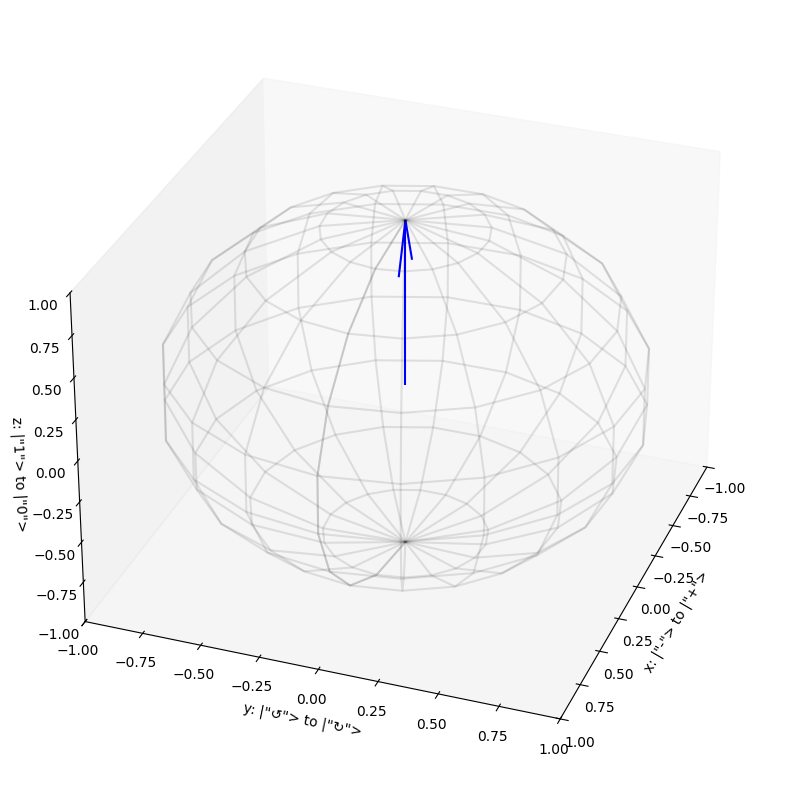

In [7]:
plot_bloch(zero_qubit)

<Axes3D: xlabel='x: |"-"> to |"+">', ylabel='y: |"↺"> to |"↻">', zlabel='z: |"1"> to |"0">'>

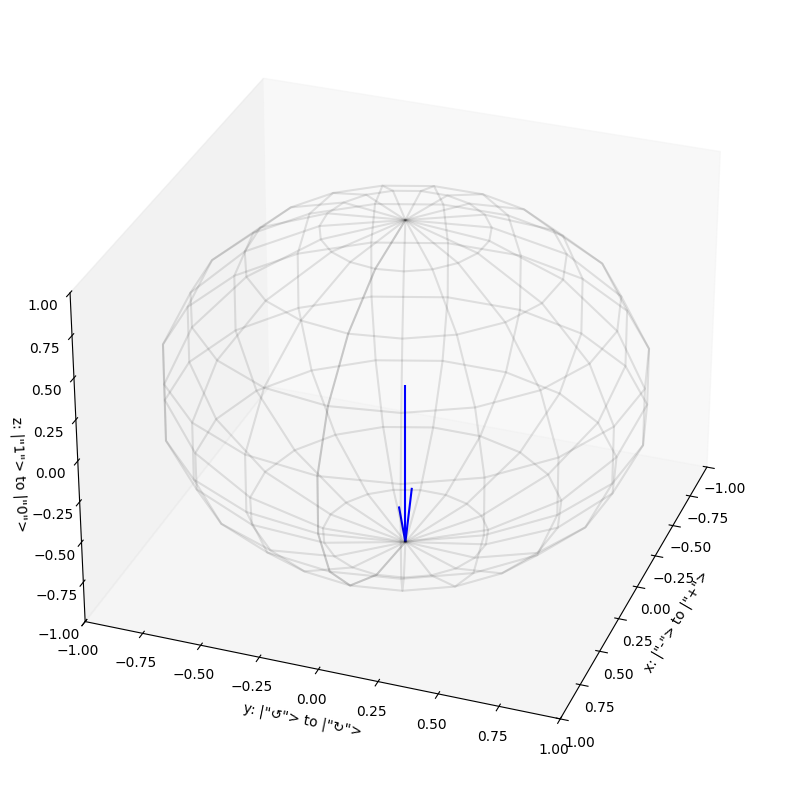

In [8]:
plot_bloch(one_qubit)

Now a qubit of our own: $\alpha = \sqrt{0.8}$ and $\beta = -i \sqrt{0.2}$, so 80% $|0\rangle$ and 20% $|1\rangle$.

<Axes3D: xlabel='x: |"-"> to |"+">', ylabel='y: |"↺"> to |"↻">', zlabel='z: |"1"> to |"0">'>

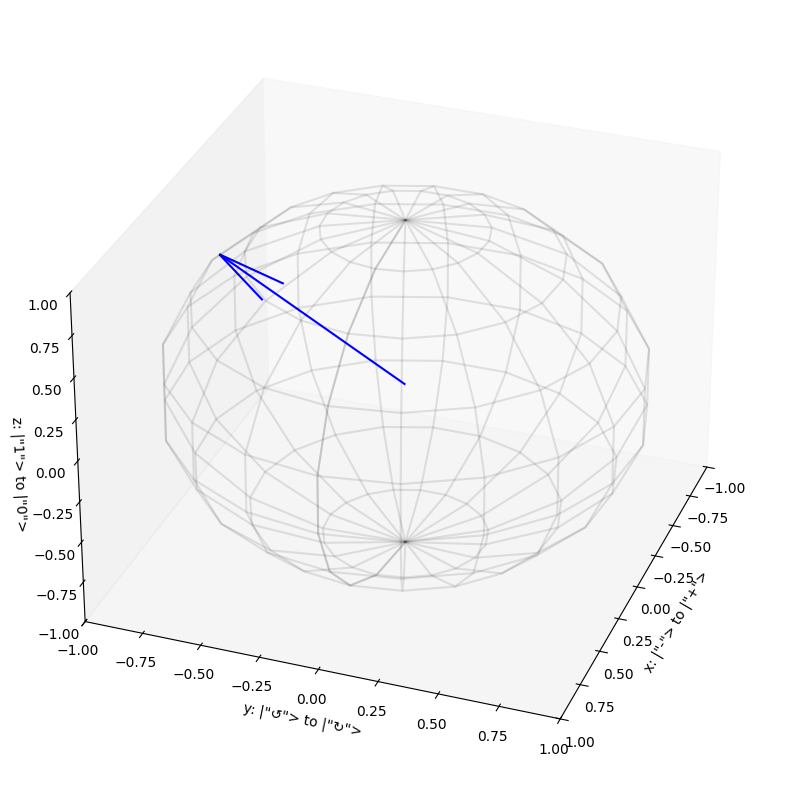

In [9]:
eighty_twenty_qubit = np.sqrt(0.8)*zero_qubit - i_ * np.sqrt(0.2)*one_qubit
plot_bloch(eighty_twenty_qubit)

**Exercise:** Play with this code and draw some new qubits. Remember that $\alpha^* \alpha + \beta^* \beta = 1$.

### Measurement

Formally: a measurement picks a _basis_ (say $|0\rangle$ and $|1\rangle$) and always returns one of its states, with probability equal to the squared amplitude. The superposition collapses, so measuring again gives the same result.

For our qubit above, that's an 80% chance of $|0\rangle$ and 20% of $|1\rangle$.

Quantum mechanics is weird! Read how this was discovered in the [Stern–Gerlach experiment](https://en.wikipedia.org/wiki/Stern%E2%80%93Gerlach_experiment).

## Quantum circuits - lines and gates

### Special rules

Quantum circuits have lines and gates like classical circuits, with two special rules:

* **No copying**: we can't duplicate a qubit (we'll see why later).
* **Reversibility**: all gates are [unitary](https://en.wikipedia.org/wiki/Unitary_operator), so every circuit can be run backwards. That rules out gates like the classical `AND`. Gates are also _norm preserving_: they keep the squared amplitudes adding up to 1.

Here is a quantum circuit. Time runs left to right, and each line is a qubit:

<img src="images/circuits/bell-pair.png" alt="The Bell pair circuit" width=350>

The `H` box acts on one qubit, and the dot joined to the circled plus acts on two. Both are _quantum gates_, the analogs of our logic gates. This circuit creates a _Bell pair_; we'll build it in code later.

### Gates are linear operators

Linear algebra is the foundation of quantum computing. (It's the foundation of a _lot_ of things.) Gates are _matrices_, and applying a gate means multiplying the state vector by its matrix. One-qubit gates are $2 \times 2$ _unitary_ matrices.

First, the _dot product_ of two vectors, and the length (_norm_) it defines. We number the entries from 0, as Python does:

$$\begin{split}
A =& \begin{pmatrix} a_0 \\ a_1 \end{pmatrix};~ B = \begin{pmatrix} b_0 \\ b_1 \end{pmatrix} \\
A \cdot B =&~ a_0 \times b_0 + a_1 \times b_1 \\
|A| =&~ \sqrt{A \cdot A} = \sqrt{a_{0}^2 + a_{1}^2}
\end{split}$$

This should look familiar...

<img src="images/pythag.png" height=400>

In "bra-ket" notation the dot product is written $\langle A | B \rangle$. The basis states are _orthonormal_:

$$
\langle 0 | 0 \rangle = \langle 1 | 1 \rangle = 1, \qquad \langle 0 | 1 \rangle = \langle 1 | 0 \rangle = 0
$$

So for $|\psi\rangle = \alpha |0\rangle + \beta |1\rangle$, normalization is just $\langle \psi | \psi \rangle = |\alpha|^2 + |\beta|^2 = 1$.

Next, matrix multiplication: dot each row of the matrix with the vector. (Entry $a_{01}$ sits in row 0, column 1.)

$$
\begin{pmatrix} a_{00} & a_{01} \\ a_{10} & a_{11} \end{pmatrix} \begin{pmatrix} b_{0} \\ b_{1} \end{pmatrix} = \begin{pmatrix} a_{00} b_0 + a_{01} b_1 \\ a_{10} b_0 + a_{11} b_1 \end{pmatrix}
$$

A gate acting on a state gives a new state ($b_0$ and $b_1$ are then the amplitudes of $|0\rangle$ and $|1\rangle$). The order of multiplication matters.

**Exercise:** Multiply

$$
\begin{pmatrix} 3 & 2 \\ 4 & -1 \end{pmatrix} \begin{pmatrix} 3 \\ 5 \end{pmatrix}
$$

### Multiple qubits

Two qubits have $2^2 = 4$ basis states, and can be in a superposition of all four:

$$
\psi = \alpha|00\rangle + \beta|01\rangle + \gamma|10\rangle + \delta|11\rangle
$$

Four amplitudes is manageable, but a molecule might need hundreds of qubits, and the count grows as $2^n$. For 200 qubits:

In [10]:
pretty_print_number(2**200)

1606938044258990275541962092341162602522202993782792835301376


The squares of the amplitudes still add up to 1, as for _every_ valid quantum state. For example:

$$
\psi = \frac{1}{\sqrt{2}} \left( |001\rangle + |110\rangle \right)
$$

Here the leftmost qubit isn't secretly 0 or 1: it's genuinely in a combination of both. That isn't just our ignorance; experiments rule out [hidden variables](https://en.wikipedia.org/wiki/Bell_test).

### Tensor products

To write multi-qubit state vectors we use the _tensor product_:

$$
|\alpha\rangle |\beta\rangle \equiv |\alpha\beta\rangle \equiv |\alpha\rangle \otimes |\beta\rangle
$$

_It's not a dot or cross product!_ It turns two 2-element vectors into one 4-element vector (and three into an 8-element one). An example shows how:

$$
\begin{pmatrix} a \\ b \end{pmatrix} \otimes \begin{pmatrix} c \\ d \end{pmatrix} =  
\begin{pmatrix} a \begin{pmatrix} c \\ d \end{pmatrix} \\ b \begin{pmatrix}  c \\ d \end{pmatrix} \end{pmatrix} =
\begin{pmatrix} ac \\ ad \\ bc \\ bd \end{pmatrix}
$$

So,

$$
|0\rangle |0\rangle =
\begin{pmatrix} 1 \\ 0 \end{pmatrix} \otimes \begin{pmatrix} 1 \\ 0 \end{pmatrix} =  
\begin{pmatrix} 1 \begin{pmatrix} 1 \\ 0 \end{pmatrix} \\ 0 \begin{pmatrix}  1 \\ 0 \end{pmatrix} \end{pmatrix} =
\begin{pmatrix} 1 \\ 0 \\ 0 \\ 0 \end{pmatrix} =
|00\rangle
$$

Matrices work the same way:

$$
\begin{pmatrix} a_1 & b_1 \\ c_1 & d_1 \end{pmatrix} \otimes \begin{pmatrix} a_2 & b_2 \\ c_2 & d_2 \end{pmatrix} =  
\begin{pmatrix} a_1 \begin{pmatrix} a_2 & b_2 \\ c_2 & d_2 \end{pmatrix} & b_1 \begin{pmatrix} a_2 & b_2 \\ c_2 & d_2 \end{pmatrix} \\ c_1 \begin{pmatrix} a_2 & b_2 \\ c_2 & d_2 \end{pmatrix} & d_1 \begin{pmatrix} a_2 & b_2 \\ c_2 & d_2 \end{pmatrix} \end{pmatrix} =
\begin{pmatrix}
a_1 a_2 & a_1 b_2 & b_1 a_2 & b_1 b_2 \\
a_1 c_2 & a_1 d_2 & b_1 c_2 & b_1 d_2 \\
c_1 a_2 & c_1 b_2 & d_1 a_2 & d_1 b_2 \\
c_1 c_2 & c_1 d_2 & d_1 c_2 & d_1 d_2 \\
\end{pmatrix}
$$

**Exercise:** work out $|0\rangle \otimes |1\rangle$ and $|1\rangle \otimes |1\rangle$

<img src="images/giphy_2.gif">

### Quantum Gates

The _Not_ gate, also called the _X_ gate:

$$
X = \begin{pmatrix} 0 & 1 \\ 1 & 0 \end{pmatrix}
$$

A sequence of gates is the product of their matrices, in order (the order matters).

It flips one basis state to the other:

$$
X |0\rangle = \begin{pmatrix} 0 & 1 \\ 1 & 0 \end{pmatrix} \begin{pmatrix} 1 \\ 0 \end{pmatrix} = \begin{pmatrix} 0 \\ 1 \end{pmatrix} = |1\rangle
$$

so two $X$ gates undo each other: $XX = I$, the identity.

The _Y_ gate:

$$
Y = \begin{pmatrix} 0 & -i \\ i & 0 \end{pmatrix}
$$

Note that $XY$ is not the same as $YX$:

$$
XY = \begin{pmatrix} 0 & 1 \\ 1 & 0 \end{pmatrix} \begin{pmatrix} 0 & -i \\ i & 0 \end{pmatrix} = \begin{pmatrix} i & 0 \\ 0 & -i \end{pmatrix}
$$

$$
YX = \begin{pmatrix} 0 & -i \\ i & 0 \end{pmatrix} \begin{pmatrix} 0 & 1 \\ 1 & 0 \end{pmatrix} = \begin{pmatrix} -i & 0 \\ 0 & i \end{pmatrix}
$$

The _Hadamard_ gate turns basis states into superpositions:

$$
H = \frac{1}{\sqrt{2}} \begin{pmatrix} 1 & 1 \\ 1 & -1 \end{pmatrix}
$$

$$
\begin{split}
H |0\rangle =&~ \frac{1}{\sqrt{2}} \left(|0\rangle + |1\rangle \right) \equiv |+\rangle  \\
H |1\rangle =&~ \frac{1}{\sqrt{2}} \left(|0\rangle - |1\rangle \right) \equiv |-\rangle  \\
\end{split}
$$

Like $X$, $H$ is its own inverse: $HH = I$.

**Exercise:** Work out $HH$ to prove $HH = I$.

<Axes3D: xlabel='x: |"-"> to |"+">', ylabel='y: |"↺"> to |"↻">', zlabel='z: |"1"> to |"0">'>

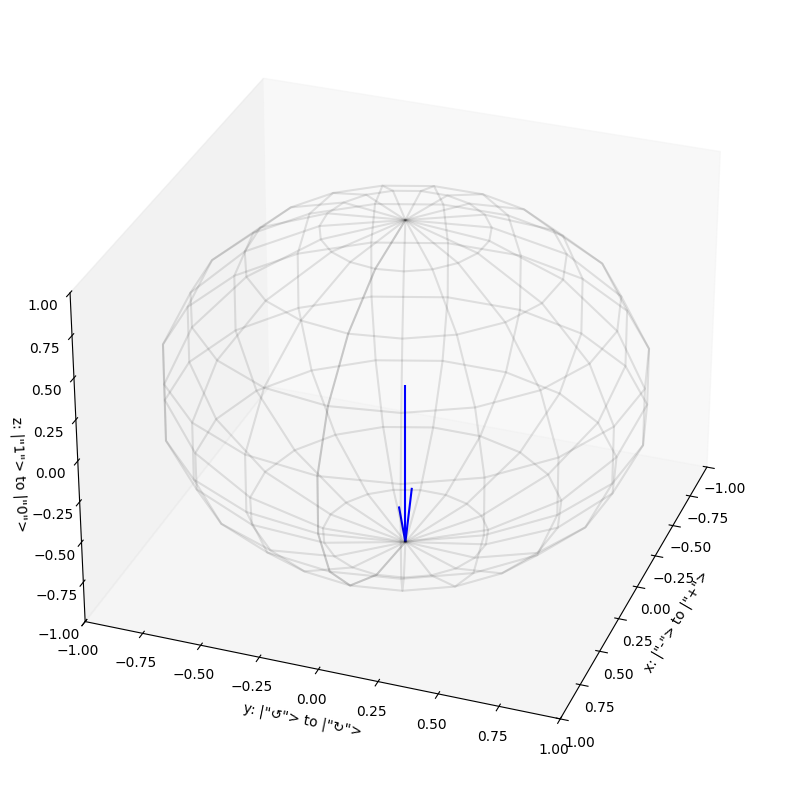

In [11]:
plot_bloch(X * zero_qubit)

<Axes3D: xlabel='x: |"-"> to |"+">', ylabel='y: |"↺"> to |"↻">', zlabel='z: |"1"> to |"0">'>

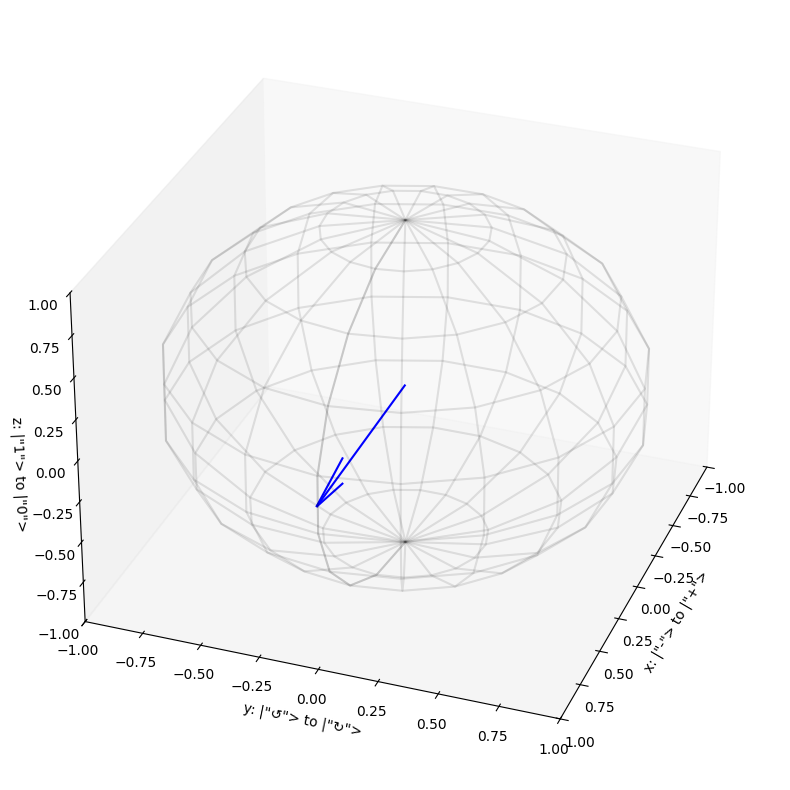

In [12]:
plot_bloch(H * zero_qubit)

<Axes3D: xlabel='x: |"-"> to |"+">', ylabel='y: |"↺"> to |"↻">', zlabel='z: |"1"> to |"0">'>

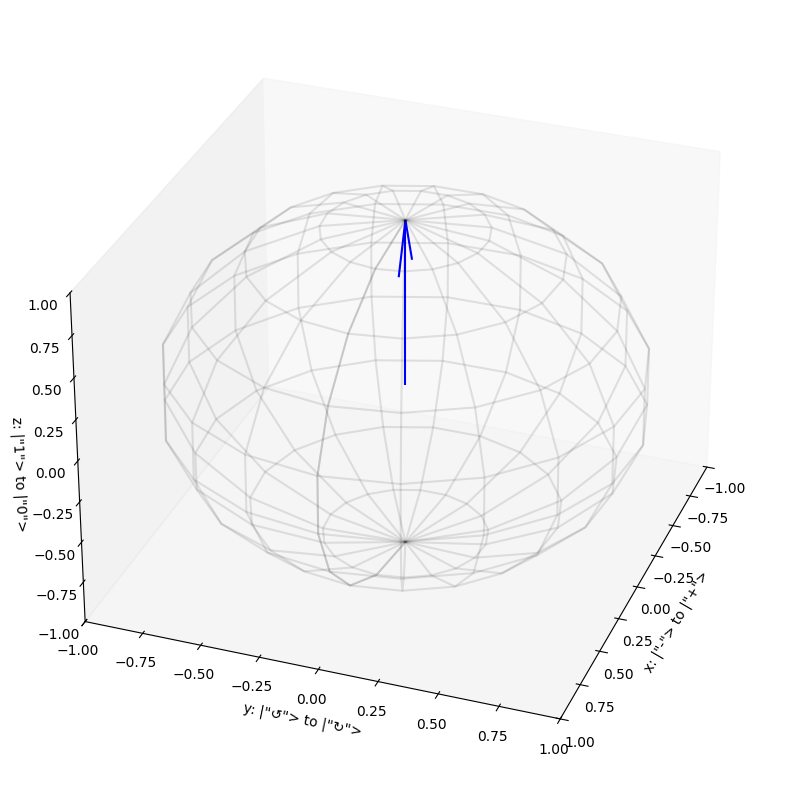

In [13]:
plot_bloch(H * H * zero_qubit)

### Two-qubit gates

Two-qubit gates are $4 \times 4$ matrices. The most important is the CNOT, or _Controlled Not_: it applies a Not to the second qubit only if the first qubit is $|1\rangle$:

$$
\begin{pmatrix}
1 & 0 & 0 & 0 \\
0 & 1 & 0 & 0 \\
0 & 0 & 0 & 1 \\
0 & 0 & 1 & 0 \\
\end{pmatrix}
$$

That makes sense once you write the two-qubit basis states as vectors:

$$
|00\rangle =
\begin{pmatrix}
1 \\
0 \\
0 \\
0 \\
\end{pmatrix},
|01\rangle =
\begin{pmatrix}
0 \\
1 \\
0 \\
0 \\
\end{pmatrix},
|10\rangle =
\begin{pmatrix}
0 \\
0 \\
1 \\
0 \\
\end{pmatrix},
|11\rangle =
\begin{pmatrix}
0 \\
0 \\
0 \\
1 \\
\end{pmatrix},
$$

Multiply them out and you'll see the CNOT leaves $|00\rangle$ and $|01\rangle$ alone and swaps $|10\rangle$ and $|11\rangle$. The CNOT is important because it lets us create _entanglement_.

### Bell pairs and entanglement

_Entanglement_ occurs when a multi-qubit state _cannot be decomposed into a product of single-qubit states_.

Many states can be split this way. For example,

$$
\begin{pmatrix} 1 \\ 0 \\ 0 \\ 0 \end{pmatrix} = |00\rangle = |0\rangle \otimes |0\rangle
$$

is just two qubits in $|0\rangle$ sitting side by side.

Every classical state can be split this way, but some quantum states can't. We call them _entangled_. For example,

$$
\frac{1}{\sqrt{2}} \left( |00\rangle + |11\rangle \right) =
\frac{1}{\sqrt{2}} \left(
    \begin{pmatrix} 1 \\ 0 \\ 0 \\ 0 \end{pmatrix} +
    \begin{pmatrix} 0 \\ 0 \\ 0 \\ 1 \end{pmatrix}
    \right) =
\frac{1}{\sqrt{2}} \begin{pmatrix} 1 \\ 0 \\ 0 \\ 1 \end{pmatrix}
$$

can't be written as a tensor product of one-qubit states. Two qubits in this state are a "Bell pair." (There are four Bell pairs, and they form a _basis_.)

**Exercise:** Try to find a tensor product of two single qubit states that produces a Bell pair. You won't find one! See if you can prove it _isn't possible_ to produce the state that way.

**Exercise:** Can you find the three other Bell basis states? Hint - we get the first one by operating on $|00\rangle$ with the Bell circuit.

### No cloning!

<img src="images/giphy_6.gif">

(We don't mean that kind of clone...)

One last thing before we write quantum programs: **we can't copy a qubit!** This is the [no-cloning theorem](https://en.wikipedia.org/wiki/No-cloning_theorem).

If you know your qubit is in a basis state (after a measurement, say), you can easily "copy" it by putting another qubit into that state. What you can't copy is an arbitrary, unknown qubit.

Suppose a unitary operator $U$ _could_ clone any state: $U|\psi\rangle |0\rangle = |\psi\rangle |\psi\rangle$. A unitary preserves inner products, so for any two states $|\psi\rangle$ and $|\phi\rangle$:

$$
\begin{split}
\langle \phi | \psi \rangle \langle 0 | 0 \rangle =&~ \langle \phi | \langle 0| | \psi \rangle | 0 \rangle \\
=&~ \langle \phi | \langle 0| U^{\dagger} U | \psi \rangle | 0 \rangle \\
=&~ \langle \phi | \psi \rangle \langle \phi | \psi \rangle \\
=&~ \left( \langle \phi | \psi \rangle \right)^2
\end{split}
$$

That holds only if $\langle \phi | \psi \rangle$ is 0 or 1: $U$ can only copy states that are identical or orthogonal (like $|0\rangle$ and $|1\rangle$), never an arbitrary one.

## QASM - Quantum Assembly Language

Okay, at long last we can start writing some quantum _programs_.

<img src="images/giphy_3.gif">

Here's a simple circuit: a Hadamard on one qubit, then a measurement (the meter):

<img src="images/circuits/hadamard-measure.png" alt="Hadamard and measure circuit" width=320>

How do we write a quantum program to run (simulate) this circuit?

[QASM](https://en.wikipedia.org/wiki/OpenQASM) is a low-level quantum programming language. It lacks fancy abstractions, but for short programs you can see exactly what's happening. (More in the [OpenQASM paper](https://arxiv.org/abs/1707.03429).)

In [14]:
#@title "Python function to read and run QASM strings [Run me!]" { display-mode: "form" }
def run_qasm_string(qasm_str, verbose=True, shots=1024):
    qc = QuantumCircuit.from_qasm_str(qasm_str=qasm_str)
    backend = AerSimulator()
    qc = qiskit.compiler.transpile(qc, backend=backend)
    job = backend.run(qc, shots=shots)
    result = job.result()
    if verbose:
        print(result.get_counts())
    return result

We'll write QASM programs as Python triple-quoted strings and pass them to our helper function.

A QASM program has four parts:

1. **Boilerplate** — `OPENQASM 2.0;` and `include "qelib1.inc";` go at the top of every program.
2. **Registers** — `qreg q[1];` allocates one qubit; `creg c[1];` allocates a classical bit to store the measurement result.
3. **Gates** — `h q[0];` applies a Hadamard to the first qubit (registers are zero-indexed arrays).
4. **Measurement** — `measure q[0] -> c[0];` measures the qubit and stores the result.

In [15]:
random_bit_qasm_str = """
OPENQASM 2.0;
include "qelib1.inc";

qreg q[1];
creg c[1];
h q[0];
measure q[0] -> c[0];
"""

In [16]:
_ = run_qasm_string(random_bit_qasm_str)

{'1': 500, '0': 524}


The Hadamard made $|+\rangle$, a superposition of $|0\rangle$ and $|1\rangle$, so measuring gives a _random_ result: roughly 50/50 over 1,024 repeated runs, or "shots."

One more: the Bell pair from earlier.

<img src="images/circuits/bell-pair.png" alt="The Bell pair circuit" width=350>

In [17]:
bell_qasm_str = """
OPENQASM 2.0;
include "qelib1.inc";

qreg q[2];
creg c[2];
h q[0];
cx q[0],q[1];
measure q[0] -> c[0];
measure q[1] -> c[1];
"""

In [18]:
_ = run_qasm_string(bell_qasm_str)

{'00': 530, '11': 494}


Only `00` and `11`: the two qubits always agree. We can check this the hard way, with linear algebra. One key point: the `H` on qubit 0 is **really** a two-qubit operation, $H \otimes I$ (the tensor product of `H` and `I`, the identity), because the full state is a four-element vector all along. The full linear algebra:

$$
(CNOT)(H_{0} \otimes I_{1})|\psi\rangle =
\begin{pmatrix}
1 & 0 & 0 & 0 \\
0 & 1 & 0 & 0 \\
0 & 0 & 0 & 1 \\
0 & 0 & 1 & 0 \\
\end{pmatrix}
\frac{1}{\sqrt{2}} \begin{pmatrix}
1 & 0 & 1 & 0 \\
0 & 1 & 0 & 1 \\
1 & 0 & -1 & 0 \\
0 & 1 & 0 & -1 \\
\end{pmatrix}
\begin{pmatrix}
1 \\
0 \\
0 \\
0 \\
\end{pmatrix}
= \frac{1}{\sqrt{2}} \begin{pmatrix} 1 \\ 0 \\ 0 \\ 1 \end{pmatrix}
$$

Note the order: $H \otimes I$ acts first (it sits next to the state), then the CNOT. Swapping them gives a different circuit.

**Exercise:** Multiply this out by hand once (including the initial step of computing $H \otimes I$). After that, use software: that's what everyone does in practice.

## Digital quantum computing

### Today's machines: noisy and analog

Our simulator is perfect; real hardware isn't. On a real device, the Bell pair would show a few `01`s and `10`s that shouldn't be there.

Today's machines have 100 to 1,000 physical qubits, and each gate goes wrong about once in 100 to 1,000 tries. Nothing fixes the errors while the program runs, so after about a thousand gates the answer is lost. These machines are _analog_: a gate is a pulse of light or microwaves that turns a qubit by any angle, and the hardware's noise sets the precision. This is the NISQ era, for Noisy Intermediate-Scale Quantum ([Preskill, 2018](https://arxiv.org/abs/1801.00862)).

### The digital way: fault tolerance

Classical computers beat noise by going _digital_. A digital quantum computer does three things:

1. **Encode** each _logical_ qubit, the one your program uses, in many _physical_ qubits.
2. **Check and correct**: keep measuring _parities_ ("do these two qubits agree?"), which locate errors without looking at the data, and fix the errors while the program runs.
3. **Compute** with a small, fixed menu of gates that work on encoded qubits.

Such a machine is _fault tolerant_: it can run programs as long as you like, like a classical computer. It works when the physical error rate is below a _threshold_ (roughly 1%): then bigger codes make logical errors exponentially rarer, as Google showed in 2024 ([Google Quantum AI, Nature 2024](https://doi.org/10.1038/s41586-024-08449-y)). The price is size: about a thousand physical qubits per logical qubit, so a million for a thousand logical ones.

**Errors are a big deal in quantum computing today, but we're on the cusp of solving them, so you all should not have to deal with them much.** We'll just assume an error-corrected, fault-tolerant gate set. To see how error correction works, go through the companion notebook, [`QuantumComputing_QEC.ipynb`](https://colab.research.google.com/github/gnperdue/SaturdayMorningQuantum/blob/main/QuantumComputing_QEC.ipynb), in your free time.

### Reading the news: physical or logical?

Headlines love qubit counts. When you read about "a 1,000-qubit chip," ask:

* **Physical or logical?** A thousand physical qubits might make one good logical qubit.
* **How good?** How often does a gate fail, and how many gates can the machine run?

IBM's roadmap, for example, aims for 100 million gates on 200 logical qubits by 2029, and a billion gates on 2,000 logical qubits in 2033 ([IBM, 2024](https://ibm.com/quantum/assets/IBM_Quantum_Developmen_&_Innovation_Roadmap_Explainer_2024-Update.pdf)).

### The fault-tolerant gate set

A fault-tolerant computer offers a short menu of gates: $H$ and $CNOT$, which you know, plus two turns of the phase of $|1\rangle$:

* $S$, a quarter turn: $S = \begin{pmatrix} 1 & 0 \\ 0 & i \end{pmatrix}$;
* $T$, an eighth of a turn: $T = \begin{pmatrix} 1 & 0 \\ 0 & e^{i\pi/4} \end{pmatrix}$.

Combinations of these four can approximate any quantum program as closely as you like. On the Bloch sphere, $S$ and $T$ turn the arrow 90° and 45° around the vertical ($z$) axis:

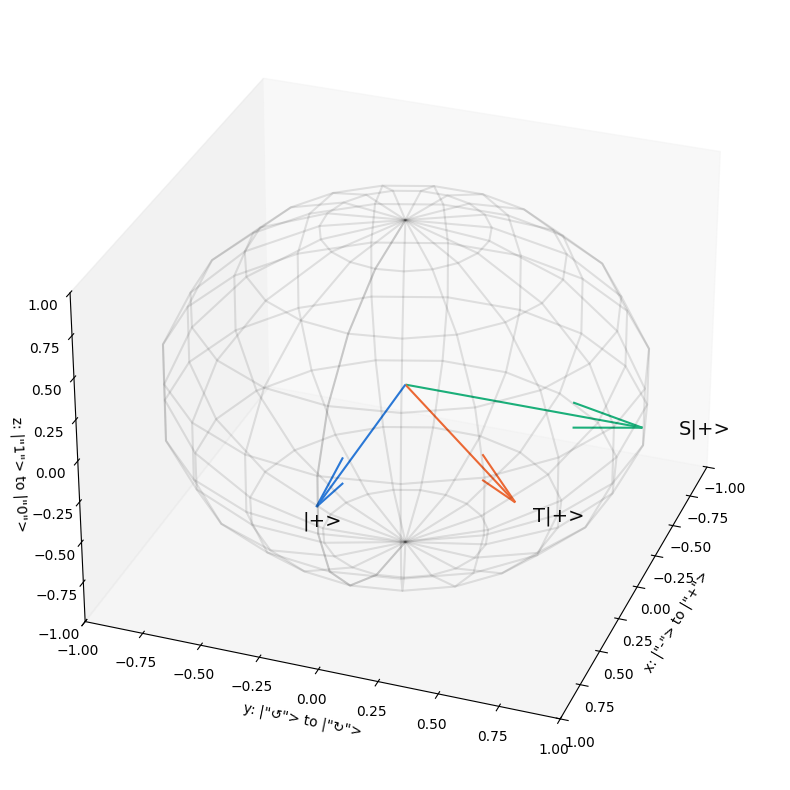

In [19]:
S = np.matrix([[1, 0], [0, i_]])
T = np.matrix([[1, 0], [0, np.exp(i_ * np.pi / 4)]])

ax = plot_bloch(plus_qubit, color='#2a78d6')
plot_bloch(T * plus_qubit, color='#eb6834', ax=ax)
plot_bloch(S * plus_qubit, color='#1baf7a', ax=ax)
for state, label in [(plus_qubit, '|+>'), (T * plus_qubit, 'T|+>'), (S * plus_qubit, 'S|+>')]:
    x, y, z = get_bloch_coordinates(state)
    ax.text(1.15 * x, 1.15 * y, 1.15 * z, label, color='#0b0b0b', fontsize=14)
plt.show()

Blue: $|+\rangle$, pointing Right. Orange: $T|+\rangle$, turned 45°. Aqua: $S|+\rangle$, turned 90°.

### Why $T$ is expensive

Circuits of only $H$, $S$ and $CNOT$ (the _Clifford_ gates) can be simulated quickly on a laptop, however many qubits they use (the [Gottesman–Knill theorem](https://en.wikipedia.org/wiki/Gottesman%E2%80%93Knill_theorem)). So $T$ is where the quantum advantage enters.

On a fault-tolerant machine the Clifford gates are cheap, because the error-correcting code can do them directly on its encoded qubits. It can't do $T$ that way. Instead, each $T$ gate uses up a _magic state_, a special qubit state that "factories" purify from many noisy copies, and the factories fill much of the machine (the [companion notebook](https://colab.research.google.com/github/gnperdue/SaturdayMorningQuantum/blob/main/QuantumComputing_QEC.ipynb) shows how). So **a program's price is its $T$ count**, and its run time is the $T$ count divided by the rate at which the factories make magic states.

### Where the software is

QASM is the _assembly language_ of quantum computing, and it's where nearly everyone starts. But a useful fault-tolerant program has about a billion $T$ gates, far too many to write out or simulate. Real programs are trees of subroutines with cost formulas attached (see Google's [Qualtran](https://github.com/quantumlib/Qualtran)), and the software that runs them on error-corrected hardware is still being invented. That's a big part of where the software work is.

## Fault-tolerant algorithms

### Where the advantage comes from

A quantum computer doesn't run "many calculations at once"; it uses _interference_. Probabilities are never negative, so paths to a wrong answer can't cancel. Amplitudes can be negative, so they can, while the paths to the right answer add up. An algorithm arranges its gates so the wrong answers cancel before the final measurement.

The smallest example: one Hadamard makes a fair coin, but two always give 0. The two paths to 1 (through $|0\rangle$ and through $|1\rangle$) have amplitudes $+\tfrac{1}{2}$ and $-\tfrac{1}{2}$, and they cancel.

In [20]:
two_hadamards_qasm_str = """
OPENQASM 2.0;
include "qelib1.inc";

qreg q[1];
creg c[1];
h q[0];
h q[0];
measure q[0] -> c[0];
"""
_ = run_qasm_string(two_hadamards_qasm_str)

{'0': 1024}


Every shot gives 0. Interference only helps when the problem has hidden structure for it to pick out, like a repeating pattern or an energy. Most problems don't, and a quantum computer won't speed them up.

### Three famous families of algorithms

* **Simulating nature** (chemistry, materials, nuclei), the application with the firmest theory. Its workhorse, _phase estimation_, reads out a system's energy as a string of bits. A neutrino calculation we costed (a carbon nucleus responding to a neutrino) needs at least 40 million $T$ gates per run.
* **Factoring** ([Shor's algorithm](https://en.wikipedia.org/wiki/Shor%27s_algorithm)) would break much of today's internet encryption. A 2025 estimate: under a million physical qubits, with 0.1% errors per gate, could factor a 2048-bit RSA key in under a week ([Gidney, 2025](https://arxiv.org/abs/2505.15917)). That's why the world is moving to "post-quantum" encryption.
* **Searching** ([Grover's algorithm](https://en.wikipedia.org/wiki/Grover%27s_algorithm)): about $\sqrt{N}$ steps instead of $N$. Real but modest, and on early fault-tolerant machines the cost of error correction eats it up ([Babbush et al., 2021](https://arxiv.org/abs/2011.04149)).

Quantum computers won't be faster at everything, as the first demo shows.

## Two demos: programming a fault-tolerant computer

Next we write QASM for a fault-tolerant computer, using only gates from the menu and counting what they cost: first an adder, then a dial with two buttons.

### Demo 1: a quantum adder

Let's add 6 and 7 again, on a quantum computer. Quantum gates must be _reversible_, and AND isn't (an output of 0 could come from 00, 01 or 10). Its quantum version is the **Toffoli** gate (`ccx`): it flips its target only when both controls are 1, so a target starting at 0 ends up holding $a$ AND $b$. The CNOT (`cx`) is a reversible XOR: it turns $b$ into $a \oplus b$.

#### A reversible full adder

Here is a reversible full adder for one column of the sum, built from two half adders like the classical one. Dots are controls and $\oplus$ is the target (two dots: a Toffoli; one dot: a CNOT). The classical OR becomes a second Toffoli onto the carry wire, which works because the two carries are never both 1.

<img src="images/circuits/reversible-full-adder.png" alt="A reversible full adder" width=600>

Three of these add two 3-bit numbers: `a[3]` and `b[3]` hold the inputs, `c[4]` the carries (and, at the end, the sum), and `total[4]` the measured answer. (Not `s`: QASM uses that name for the $S$ gate.) Here is 6 + 7:

In [21]:
adder_qasm_str = """
OPENQASM 2.0;
include "qelib1.inc";

qreg a[3];
qreg b[3];
qreg c[4];
creg total[4];

// a = 6 = 110 in binary (a[0] is the 1s place, a[1] the 2s, a[2] the 4s)
x a[1];
x a[2];
// b = 7 = 111
x b[0];
x b[1];
x b[2];

// column 0 (the 1s place)
ccx a[0],b[0],c[1];
cx a[0],b[0];
ccx b[0],c[0],c[1];
cx b[0],c[0];
cx a[0],b[0];
// column 1 (the 2s place)
ccx a[1],b[1],c[2];
cx a[1],b[1];
ccx b[1],c[1],c[2];
cx b[1],c[1];
cx a[1],b[1];
// column 2 (the 4s place)
ccx a[2],b[2],c[3];
cx a[2],b[2];
ccx b[2],c[2],c[3];
cx b[2],c[2];
cx a[2],b[2];

measure c -> total;
"""
_ = run_qasm_string(adder_qasm_str)

{'1101': 1024}


Every shot gives `1101`, binary for 13 (Qiskit prints `total[3]` on the left).

**Exercise:** Change the `x` gates to add other numbers. The next cell checks all 64 pairs of 3-bit numbers.

**Exercise:** Write out the one-column full adder from the drawing above in matrix form and verify the computation that way. Four qubits means 16x16 matrices, so feel free to use a linear algebra library on a computer, but build pieces up with tensor products and inspect the matrix elements.

In [22]:
def adder_program(a, b, superpose_a0=False):
    """The 3-bit adder above as a QASM string, for inputs a and b between 0 and 7."""
    lines = ['OPENQASM 2.0;', 'include "qelib1.inc";',
             'qreg a[3];', 'qreg b[3];', 'qreg c[4];', 'creg total[4];']
    for i in range(3):
        if (a >> i) & 1:   # is bit i of a equal to 1?
            lines.append(f'x a[{i}];')
        if (b >> i) & 1:
            lines.append(f'x b[{i}];')
    if superpose_a0:
        lines.append('h a[0];')
    for i in range(3):
        lines += [f'ccx a[{i}],b[{i}],c[{i + 1}];',
                  f'cx a[{i}],b[{i}];',
                  f'ccx b[{i}],c[{i}],c[{i + 1}];',
                  f'cx b[{i}],c[{i}];',
                  f'cx a[{i}],b[{i}];']
    lines.append('measure c -> total;')
    return '\n'.join(lines)


wrong = []
for a in range(8):
    for b in range(8):
        counts = run_qasm_string(adder_program(a, b), verbose=False, shots=16).get_counts()
        answers = [int(bits, 2) for bits in counts]
        if answers != [a + b]:
            wrong.append((a, b, answers))
print('Checked all 64 pairs. Wrong answers:', wrong if wrong else 'none')

Checked all 64 pairs. Wrong answers: none


#### Adding in superposition

A Hadamard on `a[0]` makes $a$ both 6 and 7, with $b = 7$:

In [23]:
_ = run_qasm_string(adder_program(6, 7, superpose_a0=True))

{'1101': 542, '1110': 482}


About half the shots give 13 (`1101`) and half give 14 (`1110`). The adder did both sums, but a measurement shows only one, at random. To be useful, an algorithm needs interference to make the answer you want the one you measure.

#### What does it cost?

The Toffoli isn't a Clifford gate, so it costs $T$ gates. Let's have Qiskit rewrite the adder using only menu gates ($H$, $S$, CNOT, $X$, $T$, and the inverses `sdg` and `tdg`) and count them:

In [24]:
fault_tolerant_menu = ['h', 's', 'sdg', 't', 'tdg', 'cx', 'x']

toffoli = QuantumCircuit(3)
toffoli.ccx(0, 1, 2)
toffoli_gates = qiskit.transpile(toffoli, basis_gates=fault_tolerant_menu, optimization_level=0).count_ops()
print('One Toffoli:', dict(toffoli_gates))

adder = QuantumCircuit.from_qasm_str(adder_qasm_str)
adder.remove_final_measurements()
adder_gates = qiskit.transpile(adder, basis_gates=fault_tolerant_menu, optimization_level=0).count_ops()
print('The 3-bit adder:', dict(adder_gates))
print('T count of the adder:', adder_gates.get('t', 0) + adder_gates.get('tdg', 0))

One Toffoli: {'cx': 6, 't': 4, 'tdg': 3, 'h': 2}
The 3-bit adder: {'cx': 45, 't': 24, 'tdg': 18, 'h': 6, 'x': 5}
T count of the adder: 42


A Toffoli takes 7 $T$ gates (researchers' tricks get it to about 4), so our adder costs 42, and adding two 64-bit numbers this way about 900. At a million $T$ gates per second, an optimistic guess for a future machine, that's a millisecond; your phone takes under a nanosecond.

**Quantum computers are slow at ordinary arithmetic.** But arithmetic sits inside many quantum algorithms (Shor's is mostly arithmetic), so adders are a big part of what fault-tolerant programs cost.

### Demo 2: a dial with two buttons

A fault-tolerant computer has no dial for turning a qubit by any angle you like, say 66.4°. You build the turn from the menu: $T$ turns the arrow 45° around the vertical axis, and $H$ swaps the vertical and horizontal axes, so alternating them steers the arrow almost anywhere, like parking a car whose wheel only turns in fixed steps. More $T$ gates get you closer.

#### Warm-up: a coin that lands 1 thirty percent of the time

Can we make a coin that lands 1 exactly 30% of the time using only $H$, $S$ and $T$? (A 66.4° turn around $z$ between two Hadamards would do it.) We'll try every gate sequence up to a $T$ budget and keep the best. The program is: $H$, the sequence, $H$, measure.

The search is in the file `dial_demo.py`, written so you can follow every step with pencil and paper. Open it beside this notebook; on Colab it appears in the Files panel (the folder icon) once the next cell has run. For comparison, [`dial_demo_numpy.py`](https://github.com/gnperdue/SaturdayMorningQuantum/blob/main/dial_demo_numpy.py) does the same calculations the compact NumPy way.

In [25]:
#@title "Helper: load the dial demo's code [Run me!]" { display-mode: "form" }
import os
import urllib.request

# Colab opens only this notebook, so fetch the demo's code from the course repository.
if not os.path.exists('dial_demo.py'):
    urllib.request.urlretrieve(
        'https://raw.githubusercontent.com/gnperdue/SaturdayMorningQuantum/main/dial_demo.py',
        'dial_demo.py')

from dial_demo import (best_coins, best_rotations, gate_product, plot_spin, qiskit_rotation,
                       rotation_error_degrees, sequence_as_qasm, t_count, worst_drift)

In [26]:
target = 0.30
coins = best_coins(target, max_t=10)
for budget, (chance, sequence) in enumerate(coins):
    print(f'with at most {budget:2d} T gates: the best coin lands 1 {100 * chance:6.2f}% of the time')

with at most  0 T gates: the best coin lands 1  50.00% of the time
with at most  1 T gates: the best coin lands 1  14.64% of the time
with at most  2 T gates: the best coin lands 1  25.00% of the time
with at most  3 T gates: the best coin lands 1  25.00% of the time
with at most  4 T gates: the best coin lands 1  27.14% of the time
with at most  5 T gates: the best coin lands 1  28.66% of the time
with at most  6 T gates: the best coin lands 1  31.25% of the time
with at most  7 T gates: the best coin lands 1  30.49% of the time
with at most  8 T gates: the best coin lands 1  30.49% of the time
with at most  9 T gates: the best coin lands 1  29.58% of the time
with at most 10 T gates: the best coin lands 1  30.00% of the time


With no $T$ gates we only get the fair coin. Each extra $T$ gate gives more coins to choose from, and 10 of them hit 30.00%. Let's run that program:

In [27]:
chance, sequence = coins[10]
coin_qasm_str = f"""
OPENQASM 2.0;
include "qelib1.inc";

qreg q[1];
creg c[1];
h q[0];
{sequence_as_qasm(sequence)}
h q[0];
measure q[0] -> c[0];
"""
print(coin_qasm_str)
_ = run_qasm_string(coin_qasm_str, shots=10000)


OPENQASM 2.0;
include "qelib1.inc";

qreg q[1];
creg c[1];
h q[0];
h q[0];
s q[0];
s q[0];
h q[0];
s q[0];
s q[0];
t q[0];
h q[0];
t q[0];
h q[0];
s q[0];
t q[0];
h q[0];
t q[0];
h q[0];
s q[0];
t q[0];
h q[0];
t q[0];
h q[0];
t q[0];
h q[0];
t q[0];
h q[0];
s q[0];
t q[0];
h q[0];
t q[0];
h q[0];
s q[0];
h q[0];
measure q[0] -> c[0];

{'0': 6943, '1': 3057}


That one coin took 10 $T$ gates. A real compiler's job is harder: the _whole rotation_ must be right for every starting state, not just for one coin. Here's why that matters.

#### A spin in a magnetic field

Now let's simulate physics. A spin in a magnetic field _precesses_: its arrow turns steadily around the field, like a wobbling top. With the field up ($z$) and the spin starting Right ($|+\rangle$), let it turn 18° per time step, so it points Left after 10 steps and is back after 20. The chance of finding it Left after $k$ steps is exactly $\sin^2(k \times 9°)$.

Each step, the rotation $R_z(18°)$, is built from the menu, and its small error repeats every step. How many $T$ gates per step do we need? Below: our search with at most 6 and at most 14 $T$ gates, and Qiskit's compiler (the [Ross–Selinger method](https://arxiv.org/abs/1403.2975)) for a more precise step.

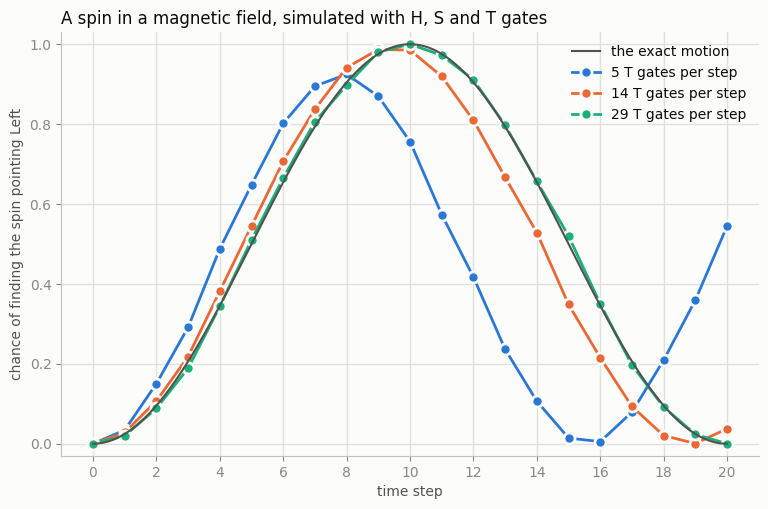

In [28]:
step_angle = 2 * np.pi / 20   # 18 degrees per time step, in radians
shots = 2048

searched = best_rotations(step_angle, max_t=14)
plotted_steps = [searched[6], searched[14], qiskit_rotation(step_angle, 1e-3)]


def spin_program(step, k):
    """QASM: start pointing Right, take k time steps, then measure Right (0) or Left (1)."""
    lines = ['OPENQASM 2.0;', 'include "qelib1.inc";', 'qreg q[1];', 'creg c[1];']
    lines.append('h q[0];')                    # point Right
    for time_step in range(k):
        lines.append(sequence_as_qasm(step))   # one time step
    lines.append('h q[0];')                    # Right becomes 0, Left becomes 1
    lines.append('measure q[0] -> c[0];')
    return '\n'.join(lines)


def measured_left(step):
    """The measured chance of finding the spin pointing Left after 0, 1, ..., 20 steps."""
    chances = []
    for k in range(21):
        counts = run_qasm_string(spin_program(step, k), verbose=False, shots=shots).get_counts()
        chances.append(counts.get('1', 0) / shots)
    return chances


measured = []
for step in plotted_steps:
    measured.append(measured_left(step))
plot_spin(step_angle, plotted_steps, measured)

With 5 $T$ gates per step, the simulated spin drifts far from the true motion; with 14 it's closer; Qiskit's 29-$T$ step sits on the exact curve, within the scatter of 2,048 shots. The table gives the numbers, with more precise steps too (the worst drift is the largest error in the chance of Left over the 20 steps, computed exactly):

In [29]:
versions = [
    ('our search, at most 6 T', searched[6]),
    ('our search, at most 9 T', searched[9]),
    ('our search, at most 14 T', searched[14]),
    ("Qiskit's compiler, error 1e-3", qiskit_rotation(step_angle, 1e-3)),
    ("Qiskit's compiler, error 1e-6", qiskit_rotation(step_angle, 1e-6)),
    ("Qiskit's compiler, error 1e-10", qiskit_rotation(step_angle, 1e-10)),
]
print(f"{'how the 18-degree step is built':32}{'T per step':>12}{'T for 20 steps':>16}"
      f"{'error per step':>16}{'worst drift':>13}")
for label, step in versions:
    error = rotation_error_degrees(gate_product(step), step_angle)
    drift = worst_drift(step, step_angle)
    print(f"{label:32}{t_count(step):>12}{20 * t_count(step):>16}{error:>15.2g}°{drift:>13.2g}")

how the 18-degree step is built   T per step  T for 20 steps  error per step  worst drift
our search, at most 6 T                    5             100             17°         0.56
our search, at most 9 T                    9             180            5.9°          0.4
our search, at most 14 T                  14             280            2.5°         0.15
Qiskit's compiler, error 1e-3             29             580          0.047°       0.0024
Qiskit's compiler, error 1e-6             62            1240        2.6e-05°      4.3e-07
Qiskit's compiler, error 1e-10           101            2020        4.3e-09°      2.2e-10


**What did that cost?** Twenty steps at 29 $T$ gates is 580 $T$ gates for one tiny simulation. Real calculations need more precise rotations: about 100 $T$ gates each at an error of one part in $10^{10}$, about 3 more per halving of the error. Cleverer methods with a helper qubit need about 36 at the precision of our neutrino calculation (one part in three million). That calculation has about 32,000 rotations per run, about 1.2 million $T$ gates, yet that's under 3% of its $T$ count: almost all the rest are Toffolis, the adder's gate.

## What to remember

**If you just want to follow the news:**

* Quantum computers don't try every answer at once. They use interference, which helps only for problems with the right structure: simulating nature, factoring, and a few others.
* Today's machines are noisy. The goal is fault tolerance: error-corrected _logical_ qubits, each made of many _physical_ ones. Ask which kind a qubit count means, and how good they are.
* Roadmaps like IBM's aim for the first large fault-tolerant machines between 2029 and 2033.

**If you might do quantum research someday:**

* A fault-tolerant program's cost is its $T$ count. Precise rotations and Toffolis are where the $T$ gates go.
* Real programs are trees of subroutines with costs attached, and tools like [Qualtran](https://github.com/quantumlib/Qualtran) work at that level. Much of that software is still to be written.
* To see how error correction makes all this possible, work through the companion notebook, [`QuantumComputing_QEC.ipynb`](https://colab.research.google.com/github/gnperdue/SaturdayMorningQuantum/blob/main/QuantumComputing_QEC.ipynb).

## Bonus: detecting a spy on a quantum network

Quantum computers aren't the only quantum technology. _Quantum networks_ send qubits from place to place, and the rules of quantum mechanics let the two ends detect an eavesdropper. This bonus section, from an earlier version of this notebook, simulates a simple spy-detection scheme.

Based on "Quantum Spy Hunter" from the book [Programming Quantum Computers](https://www.oreilly.com/library/view/programming-quantum-computers/9781492039679/) by O'Reilly.

Suppose Alice and Bob share a pair of communication channels. One can transmit classical bits and one can transmit qubits. Practically this is accomplished using an algorithm called [quantum teleportation](https://en.wikipedia.org/wiki/Quantum_teleportation). By the way, quantum teleportation is not science fiction, it is a real thing [we do at Fermilab!](https://news.fnal.gov/2020/12/fermilab-and-partners-achieve-sustained-high-fidelity-quantum-teleportation/) Sadly though we can't use it to beam ourselves anywhere...

<img src="images/giphy_7.gif">

Alice would like to send Bob some quantum information, but she fears there may be eavesdroppers on the channel. Therefore, they have agreed on an exchange protocol. Before sending sensitive data, they will send some "spy sniffer" qubits and some classical bits. The classical bits will follow an agreed upon code for a set of operations to perform on the qubits. These operations will establish whether the qubit was tampered with. Note that Alice and Bob had to agree on how to interpret these classical bits in advance, but afterwards, all of their information exchange is fully "public" (takes place on these channels).

<img src="images/nospyhunter.png">


In [30]:
pp = pprint.PrettyPrinter(indent=4)

In [31]:
no_spy_hunter_string = """
OPENQASM 2.0;
include "qelib1.inc";

// set up quantum registers - Alice, Bob, and the fiber
qreg alice[1];
qreg fiber[1];
qreg bob[1];

// set up classical registers
creg ahad[1];
creg aval[1];
creg fval[1];
creg bval[1];

// generate two random bits with Alice's QPU
reset alice[0];
h alice[0];
measure alice[0] -> ahad[0];
reset alice[0];
h alice[0];
measure alice[0] -> aval[0];

// prepare Alice's qubit - randomly create one of
// |0>, |1>, |+>, or |->, but don't say which...
reset alice[0];
if(aval==1) x alice[0];
if(ahad==1) h alice[0];

// send the qubit
swap alice[0],fiber[0];
// receive the qubit
swap fiber[0],bob[0];

// Alice sends ahad and aval to Bob.
// read the transmitted qubit
if(ahad==1) h bob[0];
if(aval==1) x bob[0];

measure bob[0] -> bval[0];
"""

In [32]:
result = run_qasm_string(no_spy_hunter_string, verbose=False)
pp.pprint(result.get_counts())
# read: 'bval fval aval ahad'

{'0 0 0 0': 263, '0 0 0 1': 253, '0 0 1 0': 250, '0 0 1 1': 258}


Interpretation: we always find '0' in Bob's measurement value (`bval`). This means he always knew the exactly correct sequence of gates to apply to de-scramble the qubit back to `|0>`. So, the qubit was never tampered with.

Now, let's introduce a spy (traditionally named "Eve") and see what happens.

<img src="images/nospyhunter-eve.png">

Eve is able to capture data in flight and she has a fully functioning quantum lab, so she can create and measure qubits and send any information she would like on the channel. Eve's goal is to capture and store sensitive quantum information.

In [33]:
spy_hunter_string = """
OPENQASM 2.0;
include "qelib1.inc";

// set up quantum registers - Alice, Bob, and the fiber
qreg alice[1];
qreg fiber[1];
qreg bob[1];

// set up classical registers
creg ahad[1];
creg aval[1];
creg fval[1];
creg bval[1];

// generate two random bits with Alice's QPU
reset alice[0];
h alice[0];
measure alice[0] -> ahad[0];
reset alice[0];
h alice[0];
measure alice[0] -> aval[0];

// prepare Alice's qubit - randomly create one of
// |0>, |1>, |+>, or |->, but don't say which...
reset alice[0];
if(aval==1) x alice[0];
if(ahad==1) h alice[0];

// send the qubit
swap alice[0],fiber[0];

// now a spy intercepts - can't see true quantum state,
// can only measure and try to replace the state.
barrier alice[0],fiber[0],bob[0];
measure fiber[0] -> fval[0];
reset fiber[0];
if(fval==1) x fiber[0];
barrier alice[0],fiber[0],bob[0];

// receive the qubit
swap fiber[0],bob[0];

// Alice sends ahad and aval to Bob. He
// inverts Alice's transformations and
// reads the transmitted qubit
if(ahad==1) h bob[0];
if(aval==1) x bob[0];

measure bob[0] -> bval[0];
"""

In [34]:
result = run_qasm_string(spy_hunter_string, verbose=False)
pp.pprint(result.get_counts())
# read: 'bval fval aval ahad'

{   '0 0 0 0': 243,
    '0 0 0 1': 74,
    '0 0 1 1': 68,
    '0 1 0 1': 52,
    '0 1 1 0': 241,
    '0 1 1 1': 76,
    '1 0 0 1': 76,
    '1 0 1 1': 61,
    '1 1 0 1': 66,
    '1 1 1 1': 67}


The interpretation is subtle and requires walking through case-by-case. Remember Alice and Bob have agreed in advance to exchange classical bits that tell Bob which quantum gates to apply to the spy-sniffer qubit Alice has sent. Bob should get the `|0>` state if he has applied the correct gates to an undisturbed qubit. If Bob ever finds a `|1>`, he knows the qubit has been tampered with and someone is listening in on their communications.

<img src="images/giphy_8.gif" height=350>


Note that because quantum mechanics is _probabilistic_ there is no guarantee every spy-sniffer qubit will reveal eavesdropping!

* `0 0 0 0` - Alice doesn't apply an H or an X, sends `|0>`. Eve measures a 0, so she sends `|0>`. Bob gets '00' from Alice and doesn't apply any gates to `|0>` and measures a '0'. **Spy not caught.**
* `0 0 0 1` - Alice applies a Hadamard and sends `|+>`. Eve measures a 0 so she sends `|0>`. Bob gets '01' from Alice, so he applies a Hadamard to `|0>` and produces `|->`, but then measures a '0' (50/50 chance). **Spy not caught.**
* `0 0 1 1` - Alice applies X and H, and sends `|->`. Eve measures 0 and sends `|0>`. Bob gets '11' from Alice, so he applies a H and then an X and produces `|+>`, but then measures a '0' (50/50 chance). **Spy not caught.**
* `0 1 0 1` - Alice applies an H and sends `|+>`. Eve measures a '1', so she sends '|1>'. Bob gets '01' from Alice, so he applies an H and produces `|->`, but then measures a '0' (50/50 chance). **Spy not caught.**
* `0 1 1 0` - Alice applies and X and sends `|1>`. Eve measures `|1>` and sends `|1>`. Bob gets `10` from Alice, so applies an X to `|1>` and gets `|0>`. **Spy not caught.**
* `0 1 1 1` - Alice applies X and H and sends `|->`.  Eve measures 1 and sends `|1>`. Bob gets '11' from Alice so he applies a H and then an X and produces `-|->`. He then measures a '0' (50/50 chance). **Spy not caught.**
* `1 0 0 1` - Alice applies an H and sends `|+>`. Eve measures 0 and so sends `|0>`. Bob gets '01' from Alice so he applies an H to produce `|+>` and measures a '1' (50/50 chance). **Spy is caught!**
* `1 0 1 1` - Alice applies X and H, and sends `|->`. Eve measures 0 and sends `|0>`. Bob gets '11' from Alice, so he applies a H and then an X and produces `|+>`, and then measures a '1' (50/50 chance). **Spy is caught!**
* `1 1 0 1` - Alice applies an H and sends `|+>`. Eve measures a '1', so she sends '|1>'. Bob gets '01' from Alice, so he applies an H and produces `|->`, and then measures a '1' (50/50 chance). **Spy is caught!**
* `1 1 1 1` - Alice applies X and H and sends `|->`.  Eve measures 1 and sends `|1>`. Bob gets '11' from Alice so he applies a H and then an X and produces `-|->`. He then measures a '1' (50/50 chance). **Spy is caught!**

So, what was the chance of catching the spy with any given sniffer qubit? We can use some Python to query the dictionary the simulator returned:

In [35]:
times_caught = 0
for i in result.get_counts().items():
    if i[0][0] == '1':
        times_caught += i[1]
print('The spy was caught {} times,'.format(times_caught))
prob_of_catching = times_caught / 1024.0
print('---> = {}% of the times we sent a spy-hunter qubit.'.format(prob_of_catching * 100))

The spy was caught 270 times,
---> = 26.3671875% of the times we sent a spy-hunter qubit.


So, if the spy has a roughly 25% chance of being caught with each spy-hunter qubit, how many spy-hunter qubits do Alice and Bob need to exchange? Theoretically, an infinite number, but suppose they were okay with a 99.999% chance of catching a spy. How many do they need to send?

It is easiest to solve this sort of probability problem not as what is the chance of 'one catch' plus 'two catches', etc., but rather as 100% minus the probability of 'no catches'. Imagine you sent one qubit, you have roughly 75% chance of missing the spy. If you send two, you have a 75% times 75% equals 56% chance of missing the spy, so a 44% chance of catching the spy. Every qubit you send reduces the chances of missing the spy, with the chance of the spy slipping through dropping by 3/4 with each qubit.

In [36]:
threshold = 0.99999
prob_of_catching = 0.25   # exact probability, not our estimate

def F(x):
    return (1 - (1 - prob_of_catching)**x) - threshold

num_times = scipy.optimize.bisect(F, 1, 50); num_times

40.0196138982692

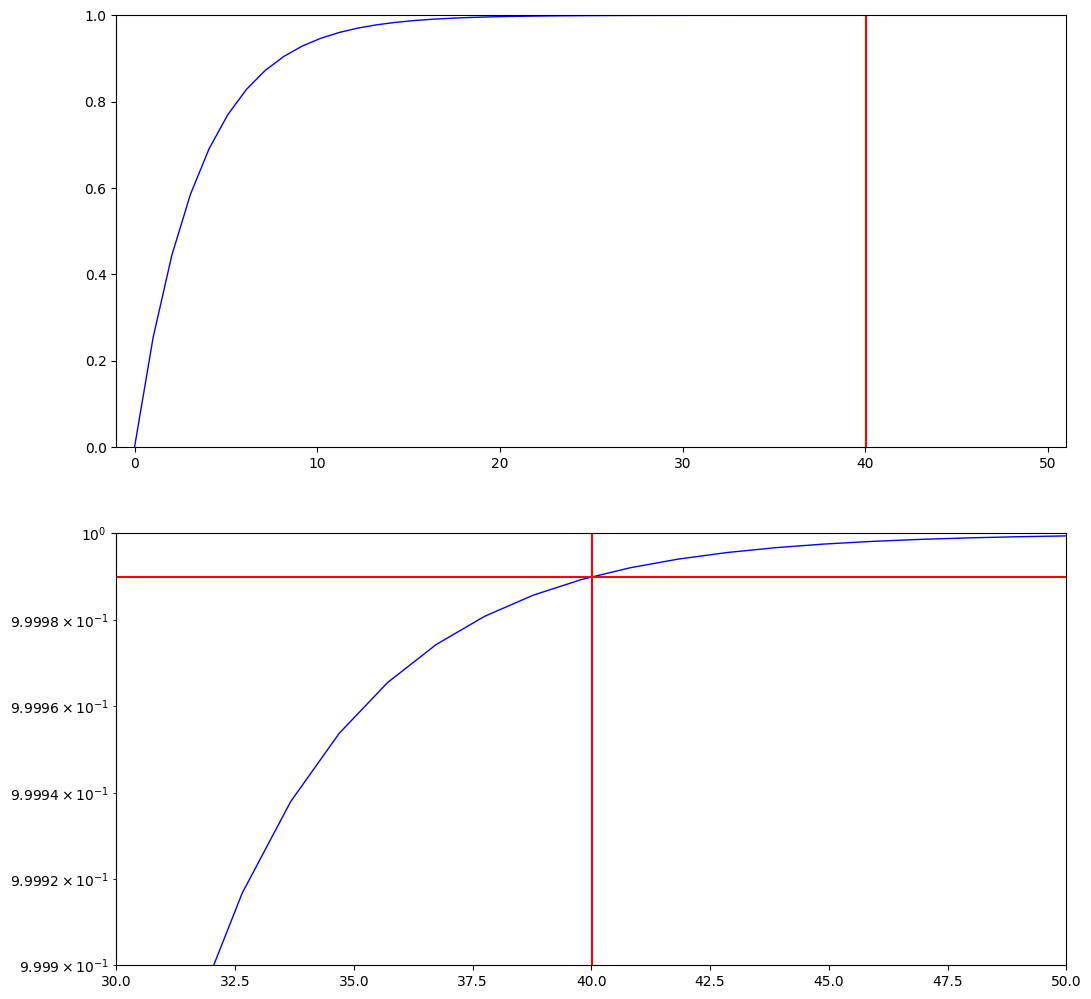

In [37]:
x = np.linspace(0, 50)
y = 1 - (1 - prob_of_catching)**x
fig = plt.figure(figsize=(10, 10))
fig.subplots_adjust(bottom=0.025, left=0.025, top=0.975, right=0.975)

ax1 = plt.subplot(2, 1, 1)
plot1, = plt.plot(x, y, color='blue', linewidth=1)
ax1.set_xlim([-1, 51])
ax1.set_ylim([0, 1])
ax1.axvline(x=num_times, color='red')

ax2 = plt.subplot(2, 1, 2)
plot2, = plt.plot(x, y, color='blue', linewidth=1)
ax2.set_xlim([30, 50])
ax2.set_ylim([0.9999, 1])
ax2.set_yscale('log')
ax2.axhline(y=threshold, color='red')
ax2.axvline(x=num_times, color='red')

If you have a quantum communication channel this is a pretty cheap check to see if there are eavesdroppers. 2 classical bits plus 1 qubit, sent about 40 times. Note we don't even care if the classical channel is observed. Because Eve doesn't know what '00', '01', etc. _mean_, there is nothing she can do with that information. If you're worried she might guess, don't use common gates like `H` and `X`, but "rotate" them by some pre-agreed angle. Eve has to guess that angle (as a real number) **exactly**. (However, there is always some classical information that Alice and Bob have to agree on in advance and keep secret --- so maybe Eve's best bet is good old-fashioned human espionage.)

Also note - Eve has no way to predict the classical _sequence_ of 'xy' bits. Resolving the qubit is a truly random process. Most "random" computational processes are not actually random - they are pseudorandom and use generators that have patterns built in. Those patterns may be quite long, but they're there, and if Eve observed long enough, she could find a pattern. There is absolutely no pattern to the classical bits Alice is sending!